# Triagem Clínica Híbrida: regras + aprendizado supervisionado

**Disciplina:** Inteligência Artificial e LFA (UDF) · Sistema Especialista de Triagem Clínica (inspirado no Protocolo de Manchester)

Este notebook mostra como o **modelo supervisionado** (Regressão Logística) se encaixa no sistema especialista:

1. o modelo estima o **nível de risco** (`baixo`, `medio`, `alto`) a partir dos mesmos fatos que o motor usa;
2. a previsão, se tiver confiança suficiente, entra no motor como um **fato** (`risco_ml`);
3. as regras **HY1/HY2** só podem **escalonar** a prioridade. O modelo nunca rebaixa uma classificação e nunca decide Vermelho.

> ⚠️ **Dados sintéticos.** O modelo é treinado com casos fictícios (`dados/casos_sinteticos.csv`). As métricas abaixo demonstram o funcionamento do código, **não** validade clínica. Protótipo acadêmico: não substitui o profissional de saúde.

## 1. Preparação

In [1]:
import os
from pathlib import Path

# O notebook precisa rodar a partir da raiz do repositório (onde está ml_risco.py).
if not Path("ml_risco.py").exists():
    if Path("../ml_risco.py").exists():
        os.chdir("..")
    else:
        raise SystemExit("Abra o notebook na raiz do repositório (veja 'Como rodar' no README).")
print("Raiz do projeto:", Path.cwd())

import numpy as np
import matplotlib.pyplot as plt
from collections import Counter
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from sklearn.model_selection import StratifiedKFold, train_test_split

from ml_risco import (BOOLEANOS, CSV_OURO, CSV_SINTETICO, LIMIAR_CONFIANCA, MIN_CASOS, NUMERICOS,
                      QUEIXAS, ROTULOS, ModeloRisco, carregar_modelo, ler_casos)
from motor_inferencia import MotorInferencia
from triagem_hibrida import ORDEM, classificar

Raiz do projeto: /home/claude/triagem-manchester


## 2. Dados

In [2]:
casos = ler_casos(CSV_SINTETICO)
y = [rotulo for _, _, rotulo in casos]
print("Casos sintéticos:", len(casos))
print("Distribuição dos rótulos:", dict(Counter(y)))
print("Distribuição por queixa:", dict(Counter(q for q, _, _ in casos)))
ouro = ler_casos(CSV_OURO)
print(f"\nCasos de ouro (rotulados por profissional): {len(ouro)} (mínimo para sair do modo demonstração: {MIN_CASOS})")

Casos sintéticos: 600
Distribuição dos rótulos: {'alto': 129, 'baixo': 245, 'medio': 226}
Distribuição por queixa: {'dor_toracica': 114, 'ferida_curativo': 135, 'dor_abdominal': 118, 'febre': 108, 'cefaleia': 125}

Casos de ouro (rotulados por profissional): 0 (mínimo para sair do modo demonstração: 30)


## 3. Treino e teste

A divisão é **estratificada** (preserva a proporção das classes) e usa semente fixa para ser reproduzível. O conjunto de teste não participa do treino.

In [3]:
treino, teste = train_test_split(casos, test_size=0.25, random_state=42, stratify=y)
print(f"Treino: {len(treino)} casos | Teste: {len(teste)} casos")

modelo = ModeloRisco().treinar(treino)
previsoes = modelo.prever_lote(teste)
y_teste = [c[2] for c in teste]
y_prev = [p for p, _ in previsoes]

print(f"\nAcurácia no teste: {accuracy_score(y_teste, y_prev):.1%}\n")
print(classification_report(y_teste, y_prev, labels=ROTULOS, zero_division=0))

Treino: 450 casos | Teste: 150 casos

Acurácia no teste: 81.3%

              precision    recall  f1-score   support

       baixo       0.82      0.87      0.84        61
       medio       0.76      0.77      0.77        57
        alto       0.93      0.78      0.85        32

    accuracy                           0.81       150
   macro avg       0.83      0.81      0.82       150
weighted avg       0.82      0.81      0.81       150



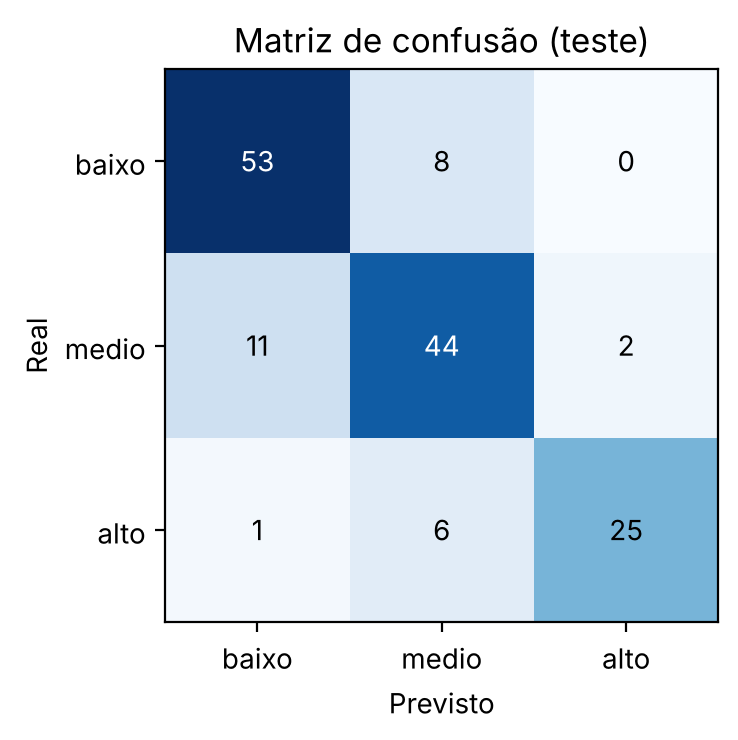

In [4]:
cm = confusion_matrix(y_teste, y_prev, labels=ROTULOS)
fig, ax = plt.subplots(figsize=(4.2, 3.8))
ax.imshow(cm, cmap="Blues")
ax.set_xticks(range(3), ROTULOS); ax.set_yticks(range(3), ROTULOS)
ax.set_xlabel("Previsto"); ax.set_ylabel("Real"); ax.set_title("Matriz de confusão (teste)")
for i in range(3):
    for j in range(3):
        ax.text(j, i, cm[i, j], ha="center", va="center", color="white" if cm[i, j] > cm.max() / 2 else "black")
plt.tight_layout(); plt.show()

## 4. Validação cruzada

Um único teste pode ser sorte. A validação cruzada estratificada (5 partições) mostra o quanto a acurácia varia.

In [5]:
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
acuracias = []
for idx_tr, idx_te in skf.split(np.zeros(len(casos)), y):
    m = ModeloRisco().treinar([casos[i] for i in idx_tr])
    prev = [p for p, _ in m.prever_lote([casos[i] for i in idx_te])]
    acuracias.append(accuracy_score([y[i] for i in idx_te], prev))
print("Acurácia por partição:", [f"{a:.1%}" for a in acuracias])
print(f"Média: {np.mean(acuracias):.1%} ± {np.std(acuracias):.1%}")

Acurácia por partição: ['88.3%', '80.8%', '79.2%', '84.2%', '85.8%']
Média: 83.7% ± 3.3%


## 5. Confiança e limiar (`LIMIAR_CONFIANCA = 0.6`)

O motor só usa a previsão do modelo quando a confiança atinge o limiar. Abaixo, o que acontece ao variá-lo: **cobertura** (fração dos casos em que o modelo é usado) × **acurácia** nesses casos.

In [6]:
conf = np.array([c for _, c in previsoes])
acerto = np.array([a == b for a, b in zip(y_teste, y_prev)])
print(f"{'limiar':>7} {'cobertura':>10} {'acurácia (nos usados)':>22}")
for lim in [0.5, 0.6, 0.7, 0.8, 0.9]:
    usados = conf >= lim
    acc = acerto[usados].mean() if usados.any() else float("nan")
    print(f"{lim:>7.2f} {usados.mean():>10.1%} {acc:>22.1%}")

 limiar  cobertura  acurácia (nos usados)
   0.50      97.3%                  81.5%
   0.60      86.7%                  85.4%
   0.70      74.7%                  89.3%
   0.80      58.7%                  90.9%
   0.90      37.3%                  92.9%


## 6. O que o modelo aprendeu

Coeficientes (padronizados) da classe `alto`: positivos aumentam a chance de risco alto. Serve para **explicar** a previsão e conferir se os pesos fazem sentido clínico.

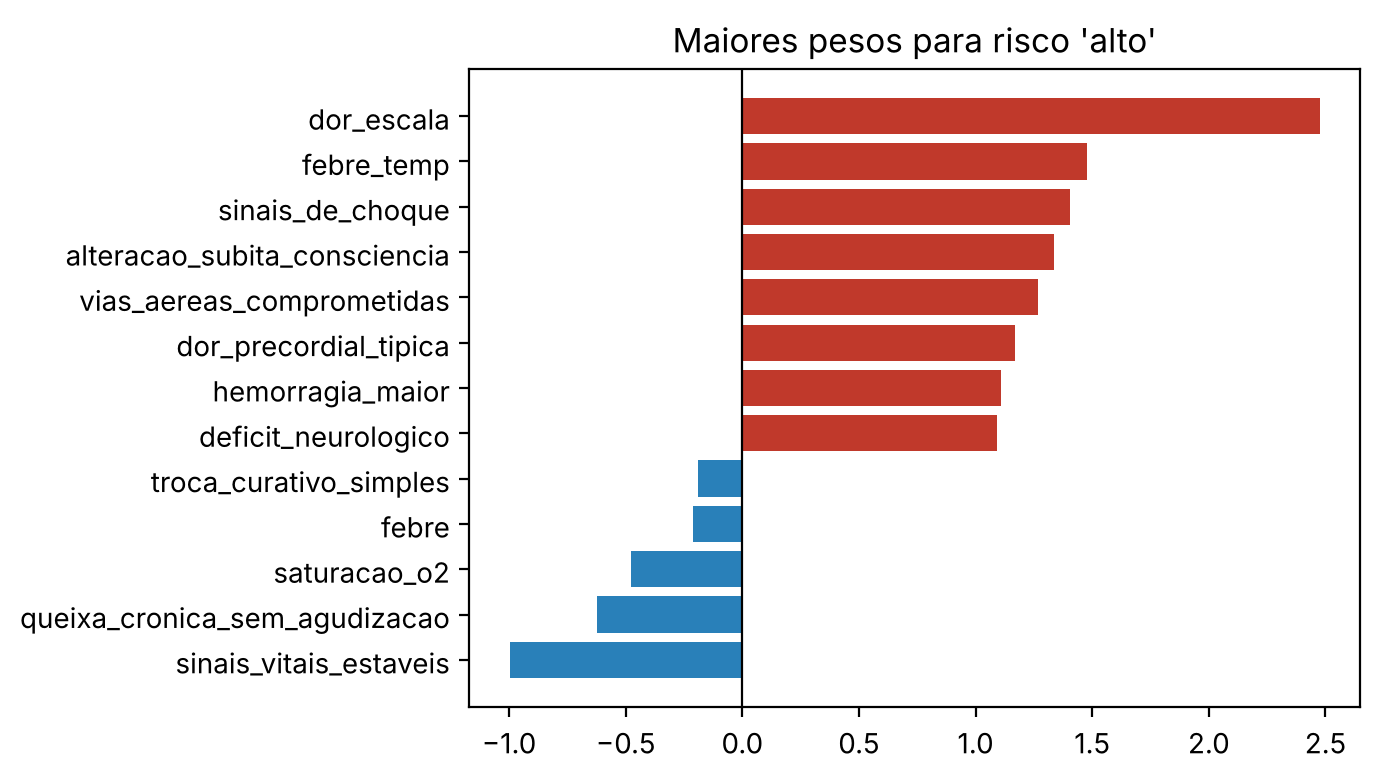

In [7]:
nomes = list(QUEIXAS) + list(NUMERICOS) + list(BOOLEANOS)
clf = modelo.pipeline.named_steps["logisticregression"]
i_alto = list(clf.classes_).index("alto")
coef = clf.coef_[i_alto]
ordem = np.argsort(coef)
selec = list(ordem[:5]) + list(ordem[-8:])
plt.figure(figsize=(7, 4))
plt.barh([nomes[i] for i in selec], [coef[i] for i in selec],
         color=["#c0392b" if coef[i] > 0 else "#2980b9" for i in selec])
plt.axvline(0, color="k", lw=0.8); plt.title("Maiores pesos para risco 'alto'")
plt.tight_layout(); plt.show()

## 7. Integração com o motor de regras

Aqui o sistema completo: `classificar()` roda o motor **sem** o modelo (só regras) e **com** o modelo (fato `risco_ml`), e mostra se houve escalonamento. Casos novos, que não estão no conjunto sintético.

In [8]:
motor = MotorInferencia()
modelo_final, fonte, demo = carregar_modelo()
print("Modelo treinado com:", fonte, "| modo demonstração:", demo, "\n")

casos_novos = {
    "A. Febre alta e persistente, sintomas gripais": ("febre", dict(
        sinais_vitais_estaveis=True, febre_temp=40.6, febre_dias=5, saturacao_o2=97, sintomas_gripais=True)),
    "B. Cefaleia leve, estável": ("cefaleia", dict(sinais_vitais_estaveis=True, dor_escala=3)),
    "C. Dor torácica leve, sinais vitais instáveis": ("dor_toracica", dict(
        sinais_vitais_estaveis=False, dor_escala=3, saturacao_o2=93, dor_precordial_tipica=False)),
}

def mostrar(titulo, queixa, fatos):
    h = classificar(motor, modelo_final, queixa, fatos)
    print(f"{titulo}\n  só regras : {h.so_regras.cor.upper():9} ({h.so_regras.regra_id})")
    print(f"  modelo    : risco {h.ml_rotulo} (confiança {h.ml_confianca:.0%}), "
          f"{'usado' if h.risco_usado else 'ignorado (abaixo do limiar)'}")
    print(f"  FINAL     : {h.final.cor.upper():9} ({h.final.regra_id})"
          f"{'  <- o modelo escalonou' if h.modelo_escalonou else ''}\n")
    return h

for titulo, (queixa, fatos) in casos_novos.items():
    mostrar(titulo, queixa, fatos)

Modelo treinado com: casos_sinteticos.csv (SINTÉTICO) | modo demonstração: True 

A. Febre alta e persistente, sintomas gripais
  só regras : AMARELO   (FE3)
  modelo    : risco medio (confiança 85%), usado
  FINAL     : AMARELO   (FE3)

B. Cefaleia leve, estável
  só regras : VERDE     (CE4)
  modelo    : risco baixo (confiança 89%), usado
  FINAL     : VERDE     (CE4)

C. Dor torácica leve, sinais vitais instáveis
  só regras : AMARELO   (F1)
  modelo    : risco medio (confiança 83%), usado
  FINAL     : AMARELO   (HY2)



### Comparação: mudar um único fato

Mantém todos os dados numéricos do caso A e altera só `sinais_vitais_estaveis`. Observe o efeito nas regras e no modelo.

In [9]:
queixa, base = casos_novos["A. Febre alta e persistente, sintomas gripais"]
for estavel in (True, False):
    mostrar(f"Caso A com sinais_vitais_estaveis = {estavel}", queixa, {**base, "sinais_vitais_estaveis": estavel})

Caso A com sinais_vitais_estaveis = True
  só regras : AMARELO   (FE3)
  modelo    : risco medio (confiança 85%), usado
  FINAL     : AMARELO   (FE3)

Caso A com sinais_vitais_estaveis = False
  só regras : AMARELO   (FE3)
  modelo    : risco alto (confiança 80%), usado
  FINAL     : LARANJA   (HY1)  <- o modelo escalonou



## 8. Verificação de segurança

Em todos os casos sintéticos, o modelo **nunca** pode rebaixar a classificação das regras nem gerar Vermelho sozinho. Esta célula confere.

In [10]:
rebaixou = vermelho_do_modelo = escalonou = 0
for queixa, fatos, _ in casos:
    h = classificar(motor, modelo_final, queixa, fatos)
    if ORDEM.index(h.final.cor) < ORDEM.index(h.so_regras.cor):
        rebaixou += 1
    if h.final.cor == "vermelho" and h.so_regras.cor != "vermelho":
        vermelho_do_modelo += 1
    escalonou += h.modelo_escalonou
print(f"Casos avaliados: {len(casos)}")
print(f"Rebaixamentos pelo modelo: {rebaixou}")
print(f"Vermelhos criados só pelo modelo: {vermelho_do_modelo}")
print(f"Escalonamentos feitos pelo modelo: {escalonou}")
assert rebaixou == 0 and vermelho_do_modelo == 0

Casos avaliados: 600
Rebaixamentos pelo modelo: 0
Vermelhos criados só pelo modelo: 0
Escalonamentos feitos pelo modelo: 11


## 9. Análises

**1. Por que as métricas obtidas com estes dados não valem como evidência clínica?**

Os 600 casos são fictícios: foram gerados por `scripts/gerar_casos_sinteticos.py` (semente fixa) e o rótulo de risco vem de uma pontuação ponderada com ruído que nós mesmos definimos. O modelo, portanto, aprende a reproduzir a nossa suposição e não a realidade clínica, o que torna a avaliação circular. A acurácia da execução salva (81,3% no teste e 83,7% ± 3,3% na validação cruzada estratificada, implementada com scikit-learn [3]) mostra que o código funciona e que o resultado é estável entre partições, mas não mede desempenho em pacientes reais. Em dados reais há sintomas atípicos, informações ausentes e rótulos que variam entre profissionais; uma avaliação válida exigiria casos reais rotulados por especialistas e um conjunto de teste nunca visto. O limiar de confiança mostra o compromisso: em 0,60 o modelo é usado em 86,7% dos casos do teste, com 85,4% de acerto neles; subir o limiar aumenta o acerto, mas reduz a cobertura (seção 5).

**2. Por que o modelo só pode escalonar, nunca rebaixar?**

Porque os erros têm custos desiguais. Na classificação de risco o atendimento é ordenado pela gravidade e não pela ordem de chegada [1][2]: subestimar um caso (um paciente grave esperando como Verde) é o erro mais perigoso, enquanto superestimar apenas antecipa um atendimento. Além disso, as regras clínicas são explícitas e auditáveis, pois cada decisão tem uma regra e uma trilha de inferência [5][6], enquanto o modelo é estatístico, foi treinado com dados sintéticos e pode errar fora do domínio de treino. Por isso ele é só um sinal adicional: ignorado com confiança baixa, limitado a Laranja/Amarelo e sem poder de decidir Vermelho. A seção 8 confere isso nos 600 casos: 0 rebaixamentos, 0 Vermelhos criados pelo modelo e 11 escalonamentos. A decisão final continua com o profissional de saúde.

**3. O que muda ao trocar os dados sintéticos por casos reais rotulados?**

- **Dados:** casos reais rotulados por profissionais em `dados/casos_rotulados_ouro.csv` (mínimo de 30 para sair do modo demonstração; para métricas confiáveis, bem mais), avaliação em casos nunca vistos e recalibração do limiar de confiança.
- **Privacidade:** informação de saúde é dado pessoal sensível na LGPD (art. 5º, II), e o tratamento deve respeitar finalidade e necessidade (art. 6º) [4]. Os casos teriam de ser anonimizados e conter só os fatos que o sistema usa, sem nome, CPF, nascimento ou prontuário, como o sistema já faz.
- **Viés:** grupos sub-representados (por exemplo crianças, idosos e gestantes, hoje fora do escopo) podem receber previsões piores, e rótulos humanos podem carregar vieses; seria preciso comparar o desempenho por grupo.
- **Validação:** revisão das regras e dos limiares por especialista e, se for pesquisa com pacientes, aprovação ética institucional.

## 10. Referências

[1] MACKWAY-JONES, K.; MARSDEN, J.; WINDLE, J. (ed.). *Emergency Triage: Manchester Triage Group*. 3. ed. Chichester: Wiley-Blackwell, 2014.

[2] BRASIL. Ministério da Saúde. *Acolhimento à demanda espontânea*. Brasília: Ministério da Saúde, 2011. (Cadernos de Atenção Básica, n. 28, v. I).

[3] PEDREGOSA, F. et al. Scikit-learn: Machine Learning in Python. *Journal of Machine Learning Research*, v. 12, p. 2825-2830, 2011. Disponível em: https://jmlr.org/papers/v12/pedregosa11a.html

[4] BRASIL. Lei nº 13.709, de 14 de agosto de 2018 (Lei Geral de Proteção de Dados Pessoais). Disponível em: https://www.planalto.gov.br/ccivil_03/_ato2015-2018/2018/lei/l13709.htm

[5] RUSSELL, S.; NORVIG, P. *Artificial Intelligence: A Modern Approach*. 4. ed. Hoboken: Pearson, 2021.

[6] BUCHANAN, B. G.; SHORTLIFFE, E. H. (ed.). *Rule-Based Expert Systems: The MYCIN Experiments of the Stanford Heuristic Programming Project*. Reading: Addison-Wesley, 1984.